In [7]:
import jax.numpy as jnp
import librosa

def create_mel_filterbank(sr, n_fft, n_mels=80, fmin=0.0, fmax=None):
    if fmax is None:
        fmax = sr / 2.0
    mel = librosa.filters.mel(
        sr=sr,
        n_fft=n_fft,
        n_mels=n_mels,
        fmin=fmin,
        fmax=fmax,
        htk=False,
        norm="slaney",
    )
    # librosa returns (n_mels, n_fft//2 + 1) -> transpose for (freq_bins, n_mels)
    return jnp.asarray(mel.T, dtype=jnp.float32)

def get_mel_spectrogram(
    y,
    sr,
    n_fft=1024,
    hop_length=160,
    n_mels=80,
    mel_filters=None,
    fmin=0.0,
    fmax=None,
    eps=1e-10,
):
    y = jnp.asarray(y, dtype=jnp.float32).squeeze()
    if y.ndim != 1:
        raise ValueError("`y` must be a 1D mono waveform.")

    if y.shape[0] < n_fft:
        y = jnp.pad(y, (0, n_fft - y.shape[0]))

    n_frames = 1 + (y.shape[0] - n_fft) // hop_length
    starts = jnp.arange(n_frames) * hop_length
    frame_idx = starts[:, None] + jnp.arange(n_fft)[None, :]
    frames = y[frame_idx]

    window = jnp.hanning(n_fft).astype(jnp.float32)
    stft_result = jnp.fft.rfft(frames * window[None, :], n=n_fft, axis=-1)
    power_spec = jnp.abs(stft_result) ** 2  # (frames, freq_bins)

    if mel_filters is None:
        mel_filters = create_mel_filterbank(
            sr=sr, n_fft=n_fft, n_mels=n_mels, fmin=fmin, fmax=fmax
        )
    mel_filters = jnp.asarray(mel_filters, dtype=jnp.float32)

    if mel_filters.shape[0] != power_spec.shape[1]:
        raise ValueError(
            f"mel_filters shape {mel_filters.shape} is incompatible with power spectrum shape {power_spec.shape}."
        )

    mel_spec = power_spec @ mel_filters  # (frames, n_mels)
    log_mel_db = 10.0 * jnp.log10(jnp.maximum(mel_spec, eps))

    # Return (n_mels, time_frames) for plotting
    return log_mel_db.T

In [8]:
import librosa

# 1. Load audio as a NumPy array (Librosa is mature and handles many formats)
# y: audio time series, sr: sampling rate
y, sr = librosa.load("IISc_SYSPINProject_te_f_AGRI_00014.wav", sr=16000) 

# 2. Convert to JAX array for GPU/TPU computation
y_jax = jnp.array(y)


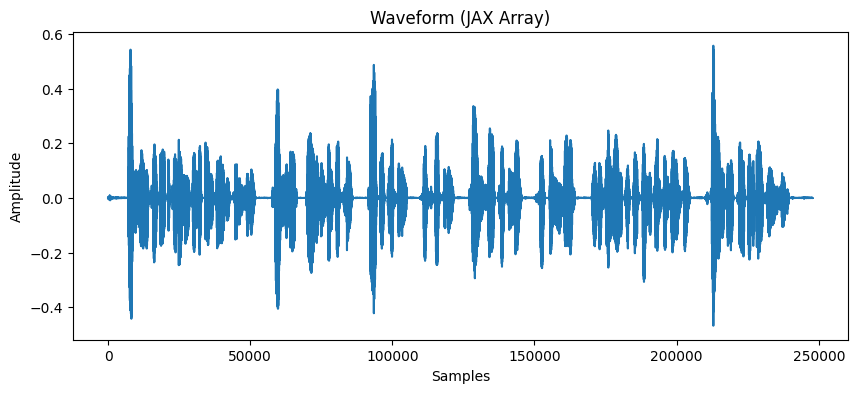

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(y_jax)
plt.title("Waveform (JAX Array)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()


In [10]:
mel_spec_db = get_mel_spectrogram(
    y_jax,
    sr=sr,
    n_fft=1024,
    hop_length=160,
    n_mels=80,
 )
mel_spec_db.shape

(80, 1543)

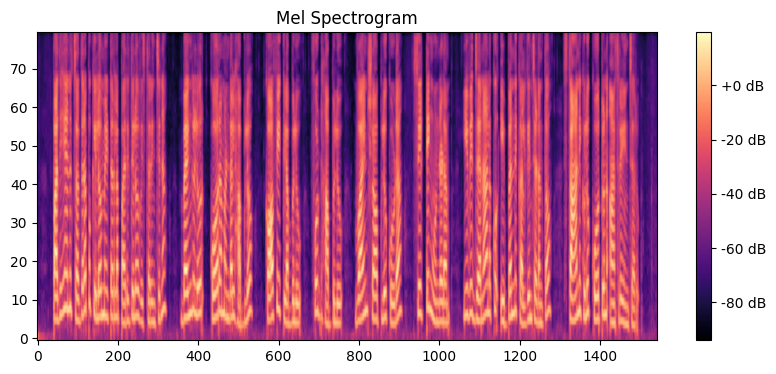

In [11]:
plt.figure(figsize=(10, 4))
plt.imshow(mel_spec_db, aspect='auto', origin='lower', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title("Mel Spectrogram")
plt.show()
